# Conception et expérimentation d'un système RAG avec LangChain, Mistral et FAISS

## Objectif du notebook

Ce notebook présente les différentes étapes de conception d'un système RAG (*Retrieval-Augmented Generation*) permettant de répondre à des questions sur les événements culturels et les activités proposés à Toulouse.

Le système s'appuie sur les événements OpenAgenda préalablement collectés, nettoyés et structurés au format JSON.

L'objectif est de construire progressivement un workflow RAG utilisant :

- **LangChain** pour organiser les documents et orchestrer les traitements ;
- **Mistral Embed** pour transformer les textes en vecteurs sémantiques ;
- **FAISS** pour indexer les vecteurs et rechercher les événements pertinents ;
- **un LLM Mistral** pour générer des réponses à partir des informations retrouvées.

## Démarche expérimentale

La conception commence par l'étude d'un événement réel afin de comprendre chaque transformation : préparation du texte, découpage en chunks, vectorisation et indexation.

Les expérimentations seront ensuite étendues à plusieurs événements pour évaluer la pertinence de la recherche sémantique.

Une attention particulière sera portée aux métadonnées (dates, lieux, accessibilité, tarifs et public), indispensables pour répondre aux contraintes précises des utilisateurs.

Les choix techniques seront validés progressivement à l'aide de visualisations et de tests, avant leur intégration dans un workflow LangChain réutilisable.

In [12]:
# ---------- Bibliothèques ----------
import json
from pathlib import Path

import pandas as pd
from IPython.display import display


# ---------- Configuration des chemins ----------
PROJECT_ROOT = Path.cwd().resolve().parents[1]
PROCESSED_DIR = PROJECT_ROOT / "App" / "Data" / "processed"

if not PROCESSED_DIR.is_dir():
    raise FileNotFoundError(
        f"Dossier processed introuvable : {PROCESSED_DIR}"
    )


# ---------- Sélection du dernier fichier processed ----------
json_files = list(PROCESSED_DIR.glob("openagenda_processed_*.json"))

if not json_files:
    raise FileNotFoundError("Aucun fichier JSON processed trouvé.")

latest_file = max(json_files, key=lambda path: path.stat().st_mtime)


# ---------- Chargement des données ----------
with latest_file.open("r", encoding="utf-8") as file:
    data = json.load(file)

events = data.get("events")

if not isinstance(events, list) or not events:
    raise ValueError("Le fichier ne contient aucune liste d'événements valide.")

if not all(isinstance(event, dict) for event in events):
    raise ValueError("La liste contient des événements au format incorrect.")


# ---------- Résumé du chargement ----------
print("Fichier chargé :", latest_file.name)
print("Nombre d'événements :", len(events))
print("Premier UID :", events[0].get("uid"))

Fichier chargé : openagenda_processed_20261009T065322835689Z.json
Nombre d'événements : 3915
Premier UID : 73281314


## 2. Construction des documents LangChain

Le jeu de données processed constitue le point d'entrée du système RAG. Les événements ont déjà été collectés, nettoyés et structurés lors des étapes précédentes.

Nous allons transformer un premier événement en objet `Document` de LangChain.

Un document contient deux parties :

- **`page_content`** : une représentation textuelle de l'événement, destinée au découpage en chunks et à la vectorisation avec Mistral Embed.
- **`metadata`** : les informations structurées de l'événement, conservées pour faciliter son identification, sa récupération et les futurs filtres métier.

Cette séparation permet d'associer une recherche sémantique à des informations précises comme les dates, les lieux et les conditions d'accès.

Dans cette première expérimentation, nous conservons toutes les informations de l'événement afin de visualiser leur organisation avant le découpage.

In [13]:
# ---------- Bibliothèques ----------
from langchain_core.documents import Document


# ---------- Sélection d'un événement ----------
event = events[0]


# ---------- Construction du texte ----------
embedding_text = "\n".join(
    f"{key} : {value}"
    for key, value in event.items()
)


# ---------- Construction des métadonnées ----------
metadata_fields = [
    "uid",
    "title",
    "slug",
    "timings",
    "date_range",
    "location_name",
    "address",
    "postal_code",
    "city",
    "district",
    "latitude",
    "longitude",
    "event_types",
    "keywords",
    "public",
    "age_min",
    "age_max",
    "accessibility",
    "conditions",
    "billetterie",
    "access",
    "event_links",
    "online_access_link",
    "location_website",
    "status",
    "origin_agenda",
]

metadata = {
    key: event[key]
    for key in metadata_fields
}


# ---------- Création du document LangChain ----------
document = Document(
    page_content=embedding_text,
    metadata=metadata,
)


# ---------- Visualisation ----------
print("UID :", document.metadata["uid"])
print("Longueur du texte :", len(document.page_content), "caractères")

print("\n---------- MÉTADONNÉES ----------")
for key, value in document.metadata.items():
    print(f"{key} : {value}")

print("\n---------- CONTENU DU DOCUMENT ----------")
print(document.page_content)

UID : 73281314
Longueur du texte : 2756 caractères

---------- MÉTADONNÉES ----------
uid : 73281314
title : Petits mondes lumineux, Cie Les Bricoleuses
slug : petits-mondes-lumineux-cie-les-bricoleuses
timings : [{'end': '2026-10-27T11:15:00+01:00', 'id': 'WXAET9', 'begin': '2026-10-27T10:30:00+01:00'}]
date_range : Mardi 27 octobre, 10h30
location_name : Muséum de Toulouse
address : 35 allées Jules Guesde, 31000 Toulouse
postal_code : 31400
city : Toulouse
district : Saint-Michel / Le Busca / Empalot / Saint-Agne / Ile du Ramier
latitude : 43.594193
longitude : 1.448929
event_types : ['Spectacle - Musique']
keywords : ['vacance', "vacances d'automne", 'accessibilité', 'cognitif et psychique', 'expo minéraux', 'spectacles']
public : ['Jeune Public']
age_min : 0
age_max : 3
accessibility : ['Handicap intellectuel', 'Handicap psychique']
conditions : Inclus dans le billet d'entrée, inscription uniquement le jour même sur place
billetterie : 
access : Métro : ligne B - station Carmes ou 

## 3. Découpage des documents avec LangChain

Le chunking consiste à découper les documents en fragments de texte avant leur vectorisation avec Mistral Embed.

Nous utilisons `RecursiveCharacterTextSplitter`, un composant de LangChain qui privilégie les séparations naturelles du texte.

Nous expérimentons une taille maximale de **1 000 caractères** par chunk, avec un chevauchement de **150 caractères** pour préserver une partie du contexte entre les fragments.

Chaque chunk conserve les métadonnées de son événement d'origine.

L'objectif est d'analyser la qualité du découpage avant de choisir les paramètres qui seront utilisés pour l'ensemble des événements OpenAgenda.

c:\Users\Philippe MAGNE\Desktop\OPENCLASSROOMS\PROJET 7\TP_chatbot_intelligent\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Nombre de chunks : 5
Chunk 1 : 323 caractères
Chunk 2 : 976 caractères
Chunk 3 : 119 caractères
Chunk 4 : 990 caractères
Chunk 5 : 461 caractères


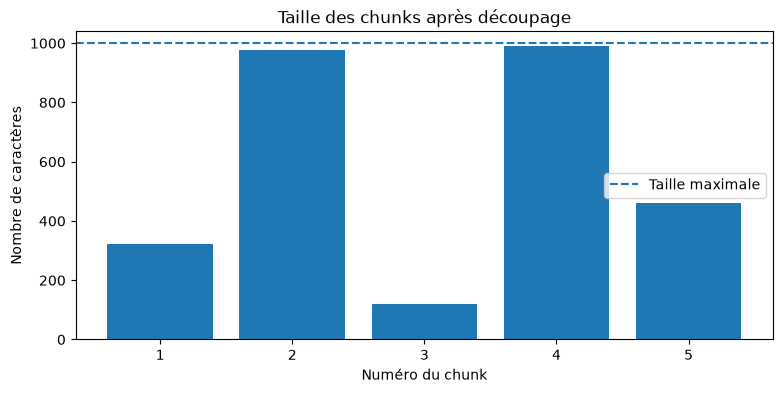


==================== CHUNK 1 ====================
uid : 73281314
title : Petits mondes lumineux, Cie Les Bricoleuses
description : Spectacle sous forme d'installation artistique pour les tout-petits au Muséum.
long_description : ### **Petits mondes lumineux est une installation pour 102 livres, 80 cailloux, 3 artistes, plein d’enfants et tous ceux qui les accompagnent.**

UID : 73281314

==================== CHUNK 2 ====================
Un opus intime qui cherche à éclairer les premières découvertes des tout-petits, la poésie de leurs premiers pas.  
C’est une invitation à la lecture et à la rêverie, une proposition atypique où différentes formes s’alternent et se superposent : spectacle, lectures, impromptus et installation dans laquelle le public peut agir. Trois artistes accompagnent pianissimo cette exploration. Elles fabriquent des chemins sonores, tactiles et lumineux pour amener le public à découvrir les livres présents dans l’installation, sur le toit d’une cabane, au creux d’

In [14]:
# ---------- Bibliothèques ----------
import matplotlib.pyplot as plt
from langchain_text_splitters import RecursiveCharacterTextSplitter


# ---------- Configuration du chunking ----------
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=1000,
    chunk_overlap=150,
    separators=["\n\n", "\n", ". ", " ", ""],
)


# ---------- Découpage du document ----------
chunks = text_splitter.split_documents([document])


# ---------- Résumé ----------
print("Nombre de chunks :", len(chunks))

for index, chunk in enumerate(chunks, start=1):
    print(f"Chunk {index} : {len(chunk.page_content)} caractères")


# ---------- Visualisation ----------
chunk_sizes = [len(chunk.page_content) for chunk in chunks]

plt.figure(figsize=(9, 4))
plt.bar(range(1, len(chunks) + 1), chunk_sizes)
plt.axhline(1000, linestyle="--", label="Taille maximale")
plt.xlabel("Numéro du chunk")
plt.ylabel("Nombre de caractères")
plt.title("Taille des chunks après découpage")
plt.xticks(range(1, len(chunks) + 1))
plt.legend()
plt.show()


# ---------- Contenu des chunks ----------
for index, chunk in enumerate(chunks, start=1):
    print(f"\n{'=' * 20} CHUNK {index} {'=' * 20}")
    print(chunk.page_content)
    print(f"\nUID : {chunk.metadata['uid']}")

Nombre de chunks : 4
73281314_1 | Présentation | 383 caractères
73281314_2 | Informations pratiques | 938 caractères
73281314_3 | Public et accessibilité | 313 caractères
73281314_4 | Description longue | 1492 caractères


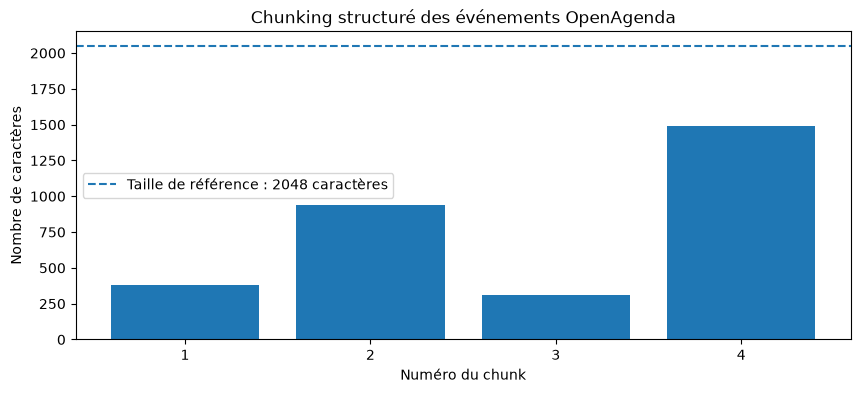


==================== 73281314_1 ====================
Section : Présentation
Taille : 383 caractères
Précédent : None
Suivant : None

Événement : Petits mondes lumineux, Cie Les Bricoleuses
Section : Présentation
title : "Petits mondes lumineux, Cie Les Bricoleuses"
description : "Spectacle sous forme d'installation artistique pour les tout-petits au Muséum."
keywords : ["vacance", "vacances d'automne", "accessibilité", "cognitif et psychique", "expo minéraux", "spectacles"]
event_types : ["Spectacle - Musique"]

==================== 73281314_2 ====================
Section : Informations pratiques
Taille : 938 caractères
Précédent : None
Suivant : None

Événement : Petits mondes lumineux, Cie Les Bricoleuses
Section : Informations pratiques
uid : 73281314
timings : [{"end": "2026-10-27T11:15:00+01:00", "id": "WXAET9", "begin": "2026-10-27T10:30:00+01:00"}]
date_range : "Mardi 27 octobre, 10h30"
location_name : "Muséum de Toulouse"
address : "35 allées Jules Guesde, 31000 Toulouse"
post

In [16]:
# ---------- Bibliothèques ----------
import json

import matplotlib.pyplot as plt
from langchain_core.documents import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter


# ---------- Configuration ----------
MAX_CHUNK_SIZE = 2048
CHUNK_OVERLAP = 150

event = events[0]
title = event["title"]


# ---------- Organisation des champs par section ----------
sections = {
    "Présentation": [
        "title", "description", "keywords", "event_types"
    ],
    "Informations pratiques": [
        "uid", "timings", "date_range", "location_name",
        "address", "postal_code", "city", "district",
        "metropole", "department", "region",
        "latitude", "longitude", "access",
        "event_links", "online_access_link",
        "location_website", "slug", "status", "origin_agenda"
    ],
    "Public et accessibilité": [
        "public", "age_min", "age_max", "accessibility",
        "conditions", "billetterie"
    ],
}

# Conserver également les éventuels champs supplémentaires du JSON.
assigned_fields = {
    field
    for fields in sections.values()
    for field in fields
}
assigned_fields.add("long_description")

sections["Informations pratiques"].extend(
    field for field in event if field not in assigned_fields
)


# ---------- Création des chunks thématiques ----------
structured_chunks = []

for section_name, fields in sections.items():
    content = "\n".join(
        f"{field} : {json.dumps(event[field], ensure_ascii=False)}"
        for field in fields
        if field in event
    )

    structured_chunks.append(
        Document(
            page_content=(
                f"Événement : {title}\n"
                f"Section : {section_name}\n"
                f"{content}"
            ),
            metadata={
                **document.metadata,
                "section": section_name,
            },
        )
    )


# ---------- Préparation de la description longue ----------
description = event["long_description"]

# Réserver suffisamment de place pour l'en-tête et le numéro de partie.
header_template = (
    f"Événement : {title}\n"
    "Section : Description longue - partie 99999/99999\n"
)

available_size = MAX_CHUNK_SIZE - len(header_template)

if available_size <= CHUNK_OVERLAP:
    raise ValueError("La taille maximale est insuffisante pour le chunking.")


# ---------- Découpage uniquement si nécessaire ----------
if description:
    if len(description) <= available_size:
        description_parts = [description]
    else:
        description_splitter = RecursiveCharacterTextSplitter(
            chunk_size=available_size,
            chunk_overlap=CHUNK_OVERLAP,
            separators=[""],
        )

        description_parts = description_splitter.split_text(description)
else:
    description_parts = []


# ---------- Création des chunks de description ----------
for index, part in enumerate(description_parts, start=1):
    structured_chunks.append(
        Document(
            page_content=(
                f"Événement : {title}\n"
                f"Section : Description longue - partie "
                f"{index}/{len(description_parts)}\n"
                f"{part}"
            ),
            metadata={
                **document.metadata,
                "section": "Description longue",
                "part": index,
                "total_parts": len(description_parts),
            },
        )
    )


# ---------- Identification des chunks ----------
for index, chunk in enumerate(structured_chunks, start=1):
    chunk.metadata["chunk_id"] = f"{event['uid']}_{index}"
    chunk.metadata["chunk_index"] = index


# ---------- Liaison des fragments de description ----------
description_chunks = [
    chunk
    for chunk in structured_chunks
    if chunk.metadata["section"] == "Description longue"
]

for index, chunk in enumerate(description_chunks):
    chunk.metadata["previous_chunk_id"] = (
        description_chunks[index - 1].metadata["chunk_id"]
        if index > 0 else None
    )

    chunk.metadata["next_chunk_id"] = (
        description_chunks[index + 1].metadata["chunk_id"]
        if index < len(description_chunks) - 1 else None
    )


# ---------- Vérification des tailles ----------
oversized_chunks = [
    chunk
    for chunk in structured_chunks
    if len(chunk.page_content) > MAX_CHUNK_SIZE
]

if oversized_chunks:
    print(
        "Attention : certaines sections thématiques dépassent "
        f"{MAX_CHUNK_SIZE} caractères."
    )


# ---------- Résumé ----------
print("Nombre de chunks :", len(structured_chunks))

for chunk in structured_chunks:
    print(
        f"{chunk.metadata['chunk_id']} | "
        f"{chunk.metadata['section']} | "
        f"{len(chunk.page_content)} caractères"
    )


# ---------- Visualisation des tailles ----------
chunk_sizes = [
    len(chunk.page_content)
    for chunk in structured_chunks
]

plt.figure(figsize=(10, 4))

plt.bar(
    range(1, len(structured_chunks) + 1),
    chunk_sizes,
)

plt.axhline(
    MAX_CHUNK_SIZE,
    linestyle="--",
    label="Taille de référence : 2048 caractères",
)

plt.title("Chunking structuré des événements OpenAgenda")
plt.xlabel("Numéro du chunk")
plt.ylabel("Nombre de caractères")
plt.xticks(range(1, len(structured_chunks) + 1))
plt.legend()
plt.show()


# ---------- Affichage du contenu et des connexions ----------
for chunk in structured_chunks:
    metadata = chunk.metadata

    print(f"\n{'=' * 20} {metadata['chunk_id']} {'=' * 20}")
    print("Section :", metadata["section"])
    print("Taille :", len(chunk.page_content), "caractères")
    print("Précédent :", metadata.get("previous_chunk_id"))
    print("Suivant :", metadata.get("next_chunk_id"))
    print()
    print(chunk.page_content)

## 4. Vectorisation des chunks avec Mistral Embed

Après le découpage structuré des événements, nous utilisons le modèle `mistral-embed` pour convertir les fragments textuels en vecteurs numériques (*embeddings*).

Ces vecteurs représentent le contenu sémantique des chunks et permettront ensuite de rechercher les événements pertinents par similarité dans FAISS.

Nous utilisons l'intégration LangChain de Mistral afin de préparer la construction du workflow RAG.

Cette première expérimentation consiste à vectoriser les chunks d'un événement, puis à vérifier le nombre de vecteurs obtenus et leurs dimensions.

In [17]:
# ---------- Bibliothèques ----------
import os

from dotenv import load_dotenv
from langchain_mistralai import MistralAIEmbeddings


# ---------- Configuration de l'API Mistral ----------
load_dotenv()

api_key = os.getenv("MISTRAL_API_KEY")

if not api_key:
    raise ValueError("La clé MISTRAL_API_KEY est absente du fichier .env")


# ---------- Initialisation du modèle d'embeddings ----------
embeddings_model = MistralAIEmbeddings(
    model="mistral-embed",
    api_key=api_key,
)


# ---------- Vectorisation des chunks ----------
texts = [chunk.page_content for chunk in structured_chunks]

vectors = embeddings_model.embed_documents(texts)


# ---------- Vérification des résultats ----------
print("Nombre de chunks :", len(structured_chunks))
print("Nombre de vecteurs :", len(vectors))
print("Dimensions d'un vecteur :", len(vectors[0]))

assert len(vectors) == len(structured_chunks)
assert all(len(vector) == 1024 for vector in vectors)

print("\nVectorisation réussie !")

Nombre de chunks : 4
Nombre de vecteurs : 4
Dimensions d'un vecteur : 1024

Vectorisation réussie !


## 5. Indexation et recherche sémantique avec FAISS

Les chunks ont été transformés en vecteurs numériques grâce à Mistral Embed.

Nous utilisons maintenant FAISS pour stocker ces vecteurs et effectuer des recherches par similarité sémantique.

Pour cette première expérimentation, nous construisons un index à partir des vecteurs déjà générés, sans appeler une seconde fois l'API Mistral pour les documents.

Nous testerons ensuite plusieurs questions afin de vérifier si FAISS retrouve les sections pertinentes de notre événement.

In [18]:
# ---------- Bibliothèques ----------
from langchain_community.vectorstores import FAISS


# ---------- Préparation des données ----------
text_embeddings = list(zip(texts, vectors))

metadatas = [
    chunk.metadata
    for chunk in structured_chunks
]


# ---------- Création de l'index FAISS ----------
vector_store = FAISS.from_embeddings(
    text_embeddings=text_embeddings,
    embedding=embeddings_model,
    metadatas=metadatas,
)


# ---------- Vérification ----------
print("Nombre de vecteurs indexés :", vector_store.index.ntotal)

assert vector_store.index.ntotal == len(structured_chunks)

print("Index FAISS créé avec succès !")

C:\Users\Philippe MAGNE\AppData\Local\Temp\ipykernel_28276\3022487090.py:2: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.vectorstores import FAISS


Nombre de vecteurs indexés : 4
Index FAISS créé avec succès !


In [19]:
# ---------- Question de test ----------
question = "Quel spectacle est adapté aux enfants de 2 ans ?"


# ---------- Recherche des chunks pertinents ----------
results = vector_store.similarity_search_with_score(
    query=question,
    k=2,
)


# ---------- Affichage des résultats ----------
print("Question :", question)

for rank, (chunk, distance) in enumerate(results, start=1):
    print(f"\n{'=' * 20} Résultat {rank} {'=' * 20}")
    print("Section :", chunk.metadata["section"])
    print("Chunk ID :", chunk.metadata["chunk_id"])
    print("Distance FAISS :", round(float(distance), 4))
    print()
    print(chunk.page_content)

Question : Quel spectacle est adapté aux enfants de 2 ans ?

==================== Résultat 1 ====================
Section : Description longue
Chunk ID : 73281314_4
Distance FAISS : 0.4298

Événement : Petits mondes lumineux, Cie Les Bricoleuses
Section : Description longue - partie 1/1
### **Petits mondes lumineux est une installation pour 102 livres, 80 cailloux, 3 artistes, plein d’enfants et tous ceux qui les accompagnent.**

Un opus intime qui cherche à éclairer les premières découvertes des tout-petits, la poésie de leurs premiers pas.  
C’est une invitation à la lecture et à la rêverie, une proposition atypique où différentes formes s’alternent et se superposent : spectacle, lectures, impromptus et installation dans laquelle le public peut agir. Trois artistes accompagnent pianissimo cette exploration. Elles fabriquent des chemins sonores, tactiles et lumineux pour amener le public à découvrir les livres présents dans l’installation, sur le toit d’une cabane, au creux d’un caill